# 递推最小二乘

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

传感器每秒产生一个新样本，反复重新拟合全部历史数据很浪费。递推最小二乘（RLS）把过去的信息压缩到一个参数估计和一个信息矩阵里，每来一条观测就更新。

## 从批量目标到递推

设模型$y_t=\phi_t^T x+\varepsilon_t$，考虑

$$S_t(x)=\frac12\sum_{i=1}^t\lambda^{t-i}(y_i-\phi_i^Tx)^2
+\frac{\lambda^t}{2}(x-x_0)^TP_0^{-1}(x-x_0).$$

$0<\lambda\le1$是遗忘因子。$\lambda=1$保留全部信息，$\lambda<1$逐渐降低旧样本权重，也同时衰减初始先验。令$P_t$为加权信息矩阵的逆，矩阵求逆引理给出

$$K_t=\frac{P_{t-1}\phi_t}{\lambda+\phi_t^TP_{t-1}\phi_t},$$
$$\hat x_t=\hat x_{t-1}+K_t(y_t-\phi_t^T\hat x_{t-1}),$$
$$P_t=\frac1\lambda\left(P_{t-1}-K_t\phi_t^TP_{t-1}\right).$$

$P_t$在这里是逆信息矩阵；只有结合相应噪声尺度与模型假设，才可解释为参数协方差。初始$P_0$大表示先验弱，但使用有限值仍然对应一个明确的正则项。

RLS: [1.01505 2.00242] regularized batch: [1.01505 2.00242]


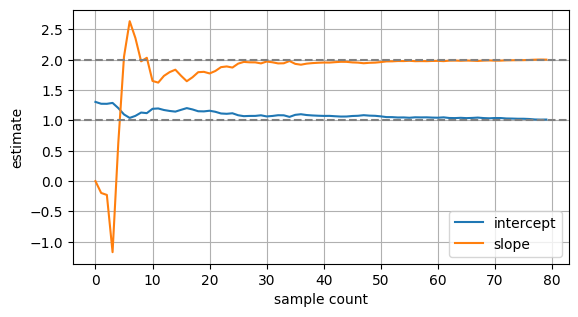

In [2]:
rng = np.random.default_rng(113)
t = np.linspace(0,5,80); A = np.column_stack([np.ones_like(t),t])
y = A@np.array([1.,2.])+rng.normal(0,.2,len(t))
beta = np.zeros(2); P = 100*np.eye(2); track=[]
for phi, yi in zip(A,y):
    beta,P = recursive_update(beta,P,phi,yi)
    track.append(beta.copy())
batch = np.linalg.solve(A.T@A+.01*np.eye(2),A.T@y)
print('RLS:',beta,'regularized batch:',batch)
assert np.allclose(beta,batch,atol=1e-10)
track=np.array(track)
plt.plot(track[:,0],label='intercept');plt.plot(track[:,1],label='slope')
plt.axhline(1,color='gray',linestyle='--');plt.axhline(2,color='gray',linestyle='--')
plt.xlabel('sample count');plt.ylabel('estimate');plt.legend();plt.show()

## 遗忘使估计能跟踪变化

如果被估参数真的随时间变化，旧数据不一定仍然代表当前系统。常数模型也可以用RLS跟踪水平变化；$\lambda$越小，适应越快，但噪声也更明显。有效记忆长度常粗略估为$1/(1-\lambda)$，这是指数权重和的量级，不是硬截断窗口。

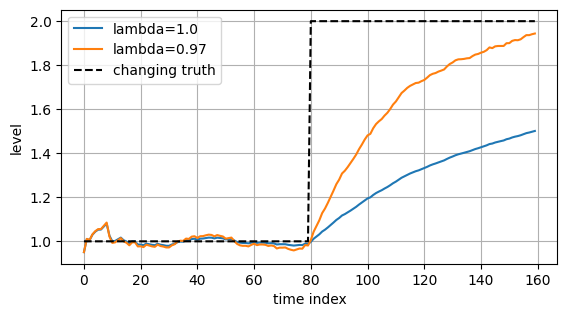

In [3]:
signal = np.r_[np.ones(80),np.full(80,2.)]
measurements = signal+rng.normal(0,.15,len(signal))
for lam in (1.,.97):
    b=np.zeros(1);p=100*np.eye(1);estimates=[]
    for yi in measurements:
        b,p=recursive_update(b,p,[1.],yi,forgetting=lam)
        estimates.append(b[0])
    plt.plot(estimates,label=f'lambda={lam}')
plt.plot(signal,'k--',label='changing truth')
plt.xlabel('time index');plt.ylabel('level');plt.legend();plt.show()

## 与卡尔曼滤波的联系和差别

常参数、线性观测、适当先验和噪声假设下，RLS可视为静态参数卡尔曼估计的一种形式。显式参数动力学和过程噪声可以表达参数如何变化；遗忘因子则用简单的统一折扣近似处理旧信息。两者有联系，但不能不说明模型就把所有RLS变体都叫同一个卡尔曼滤波器。

长时间运行可能积累对称性和正定性误差。直接相减的协方差公式在很大的初始$P$下甚至一步就可能发生消去误差。教学实现采用等价的Joseph形式：令$M=I-K_t\phi_t^T$，计算$P_t=M(P_{t-1}/\lambda)M^T+K_tK_t^T$，再对称化并检查输入正定性。这个写法对应本章单位观测噪声的信息尺度，代价是更多矩阵乘法；对高精度长期系统可研究平方根或QR形式，不能把本章的小型实现直接视为工业保证。

## 练习与解答

练习：为什么上面的批量对照多了$0.01I$？解答：$P_0=100I$，其逆为$0.01I$，初始零均值先验仍然存在。若忽略它，RLS与批量比较就不是同一个目标。

练习：$\lambda=.97$时，100步前的权重是多少？解答：约为$.97^{100}\approx0.0476$，不是零。

练习：参数不变且观测噪声独立时，是否应该总用很小的$\lambda$？解答：不应该；遗忘会舍弃有效信息，增加估计方差，只有模型确实需要适应变化时才有相应理由。